In [1]:
import torch
import torch.nn.functional as F

import cv2
import matplotlib.pyplot as plt
import numpy as np


In [2]:
device = torch.device(
    # "cuda" if torch.cuda.is_available() else "cpu"
    "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
)

In [3]:
device

device(type='mps')

In [4]:
image_np = cv2.imread("./input_imgs/Lenna_(test_image).png", cv2.IMREAD_GRAYSCALE)
image_np.shape

(512, 512)

In [5]:
# batch, ch, h, w
# out_ch, in_ch, h, w

In [8]:
x = torch.from_numpy(image_np).float().unsqueeze(0).unsqueeze(0).to(device)
x.shape

torch.Size([1, 1, 512, 512])

In [33]:
blur_kernel_3_3 = torch.ones((31,31), dtype=torch.float32)
blur_kernel_3_3 = blur_kernel_3_3.unsqueeze(0).unsqueeze(0).to(device)

sharp_kernel_3_3 = torch.tensor([
    [0, -1, 0],
    [-1, 5,-1],
    [0, -1, 0]],
    dtype=torch.float32
)
sharp_kernel_3_3 = sharp_kernel_3_3.unsqueeze(0).unsqueeze(0).to(device)
sharp_kernel_3_3.shape

torch.Size([1, 1, 3, 3])

Text(0.5, 1.0, '(512, 512)')

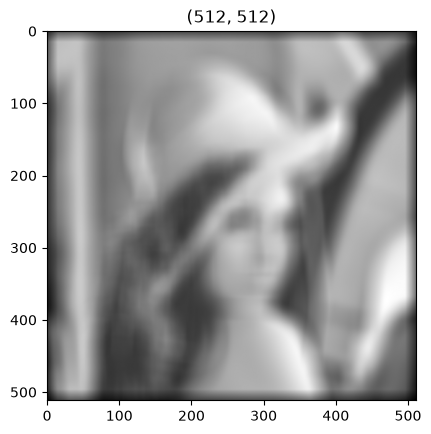

In [36]:
temp_res = F.conv2d(x, blur_kernel_3_3, stride=1, padding='same')[0][0].cpu().numpy()

plt.imshow(temp_res, cmap="gray")
plt.title(temp_res.shape)

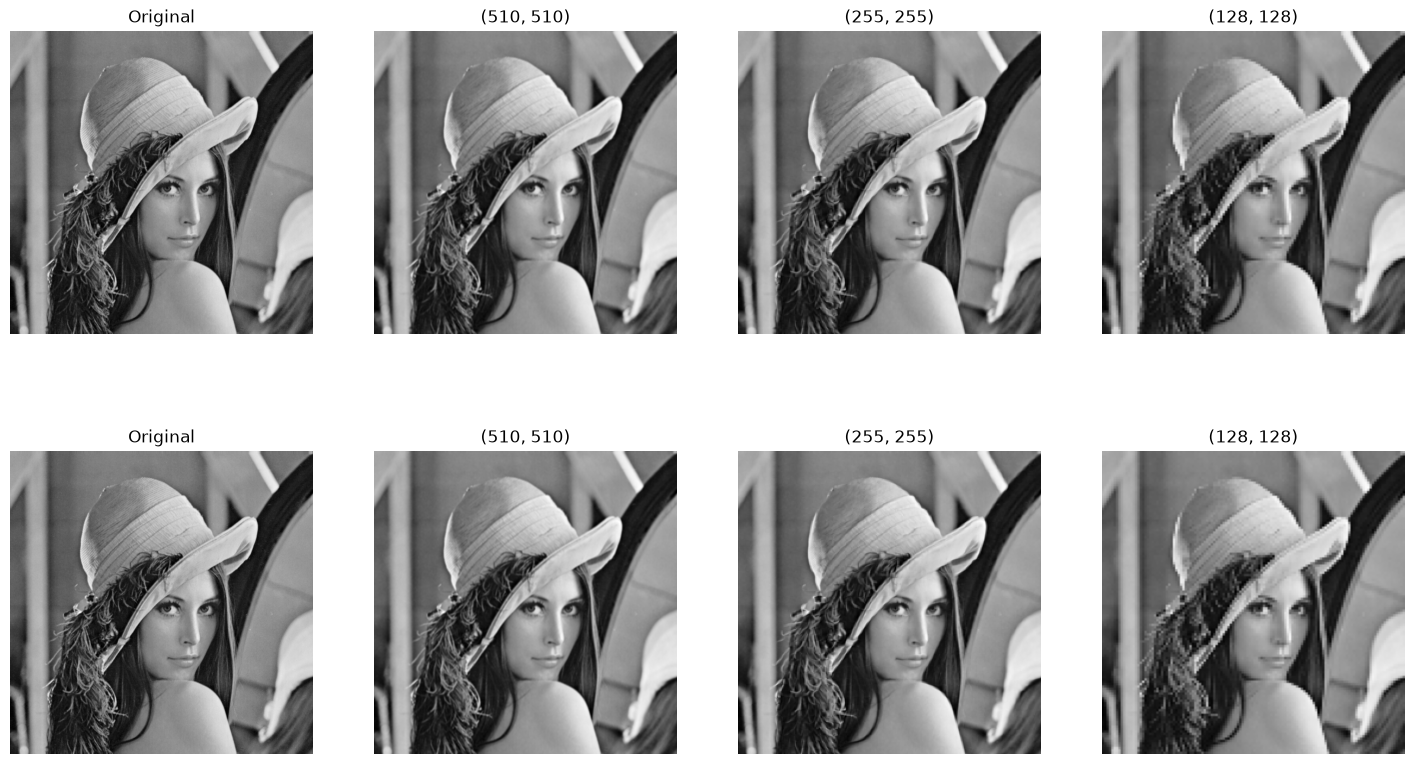

In [29]:
fig, axes = plt.subplots(2, 4, figsize=(18,10))

axes[0,0].imshow(image_np, cmap="gray")
axes[0,0].set_title("Original")

axes[1,0].imshow(image_np, cmap="gray")
axes[1,0].set_title("Original")

with torch.no_grad():
    for col, stride in enumerate([1,2,4]):

        # Blur
        y_blur = F.conv2d(x, blur_kernel_3_3, stride=stride)[0][0].cpu().numpy()

        # Sharp
        y_sharp = F.conv2d(x, sharp_kernel_3_3, stride=stride)[0][0].cpu().numpy()

        axes[0, col + 1].imshow(y_blur, cmap="gray")
        axes[0, col + 1].set_title(y_blur.shape)

        axes[1, col + 1].imshow(y_blur, cmap="gray")
        axes[1, col + 1].set_title(y_sharp.shape)

for ax in axes.flatten():
    ax.axis('off')

plt.show()

In [ ]:
torch.nn.Conv2d()
torch.nn.functional.conv2d()